In [ ]:
#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [ ]:
#load dataset
df=pd.read_csv('/content/iris (2).csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
df.shape

(150, 5)

In [ ]:
df.isnull().sum()

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


In [ ]:
print("No.of records:",df.duplicated().sum())

No.of records: 3


In [ ]:
#remove duplicate records
df.drop_duplicates(inplace=True)
df.shape

(147, 5)

In [ ]:
#idetify null values
df.isnull().sum()

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


<Axes: ylabel='sepal_length'>

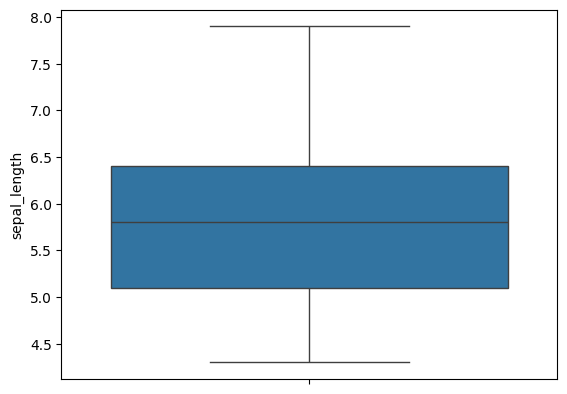

In [ ]:
#identify outliers
sns.boxplot(df['sepal_length'])

<Axes: ylabel='sepal_width'>

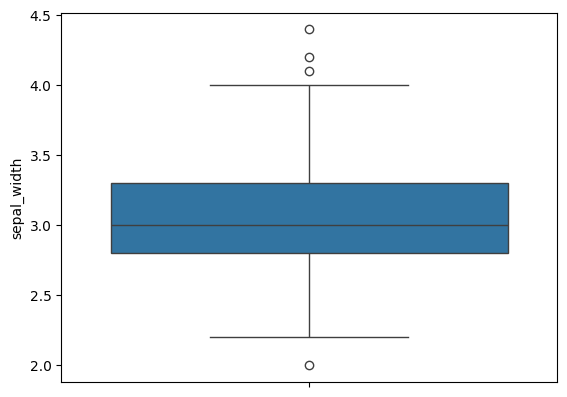

In [ ]:
#identfy outliers in sepal width
sns.boxplot(df['sepal_width'])

In [ ]:
#remove outliers in sepal width
Q1=df['sepal_width'].quantile(0.25)
Q3=df['sepal_width'].quantile(0.75)
IQR=Q3-Q1
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR
df=df[(df['sepal_width']>=lower_limit)&(df['sepal_width']<=upper_limit)]
df.shape

(143, 5)

<Axes: ylabel='sepal_width'>

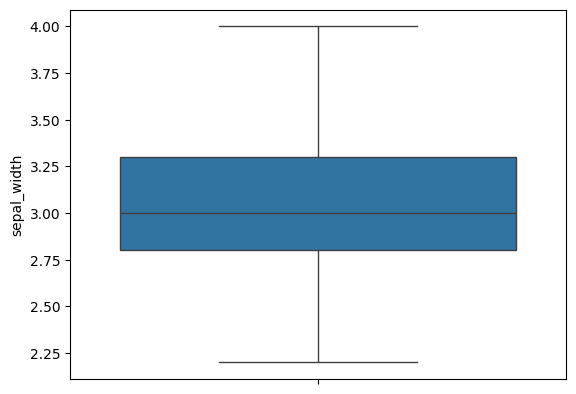

In [ ]:
#outliers in sepal width
sns.boxplot(df['sepal_width'])

<Axes: ylabel='petal_length'>

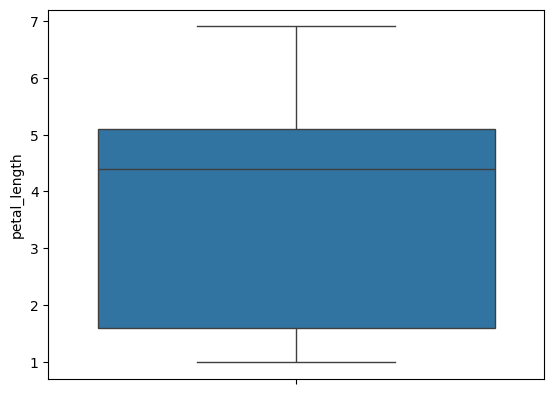

In [ ]:
#identify petal length
sns.boxplot(df['petal_length'])

<Axes: ylabel='petal_width'>

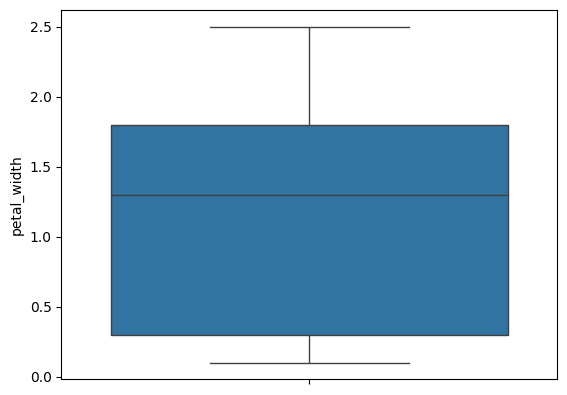

In [ ]:
#identify petal width
sns.boxplot(df['petal_width'])

In [ ]:
#label encoding for target
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['species']=le.fit_transform(df['species'])
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
x=df.iloc[:,:-1]
y=df.iloc[:,-1]

In [ ]:
#split the data into training and testing
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=15)

In [ ]:
#satndardization
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

In [ ]:
#model building
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train,y_train)

KNeighborsClassifier()

In [ ]:
#predictions on test data
y_pred=knn.predict(x_test)

In [ ]:
#evaluation metrics
accuracy_score(y_test,y_pred)
classification_report(y_test,y_pred)
confusion_matrix(y_test,y_pred)

array([[ 8,  0,  0],
       [ 0, 13,  0],
       [ 0,  0,  8]])

<Axes: >

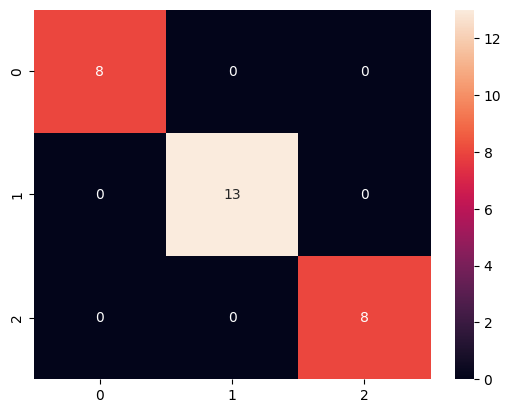

In [ ]:
#confusion matrix
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True)

In [ ]:
from sklearn.metrics import accuracy_score, roc_auc_score
y_pred = knn.predict(x_test)
y_proba = knn.predict_proba(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
roc_auc = roc_auc_score(
y_test,
y_proba,
multi_class='ovr'
)
print("ROC-AUC Score:", roc_auc)

Accuracy: 1.0
ROC-AUC Score: 1.0


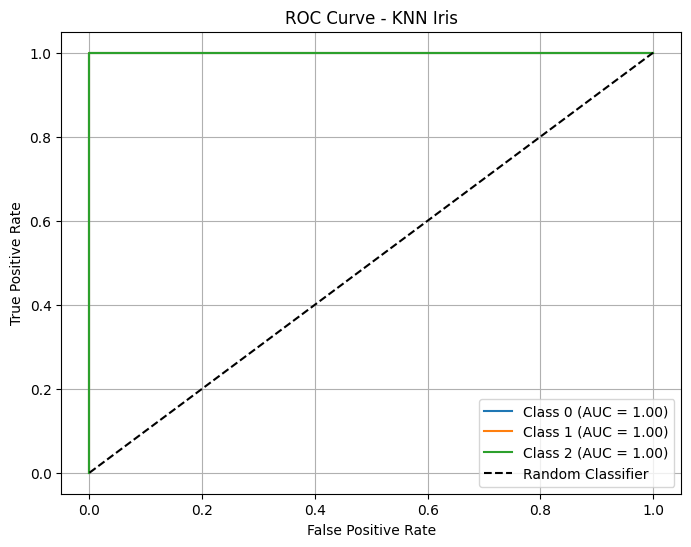

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predict probabilities
y_proba = knn.predict_proba(x_test)

# Convert test labels into binary form
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

# Plot ROC curve for each class
plt.figure(figsize=(8, 6))
for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_score = roc_auc_score(y_test_bin[:, i], y_proba[:, i])
    plt.plot(
        fpr, tpr,
        label=f'Class {i} (AUC = {auc_score:.2f})'
    )

# Random classifier
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - KNN Iris')
plt.legend()
plt.grid()
plt.show()

In [ ]:
overall_auc = roc_auc_score(y_test_bin,y_proba,multi_class='ovr')
print("Overall ROC-AUC:", overall_auc)

Overall ROC-AUC: 1.0


In [ ]:
In K-Nearest Neighbors (KNN), distance-based metrics are methods used to measure how close or similar two data points are. KNN uses these distances to find the K nearest neighbors of a new data point.

Common distance metrics in KNN

Distance Metric
Formula / Idea
Best suited for
Euclidean Distance
Straight-line distance
Continuous numerical data
Manhattan Distance
Sum of absolute differences
Grid-like data, numerical features
Minkowski Distance
Generalized form of Euclidean/Manhattan
Flexible numerical data
Chebyshev Distance
Maximum absolute difference
When the largest feature difference matters
Hamming Distance
Number of positions that differ
Categorical/binary data

1. Euclidean Distance
The most commonly used distance in KNN.
For two points:



Example:

P = (2, 3)
Q = (5, 7)

Distance = √[(2-5)² + (3-7)²]
         = √25
         = 5

2. Manhattan Distance
Also called Taxicab distance.


For the same points:

P = (2, 3)
Q = (5, 7)

Distance = |2-5| + |3-7|
         = 3 + 4
         = 7

3. Minkowski Distance
Minkowski is a generalized distance metric.



If p = 1 → Manhattan distance

If p = 2 → Euclidean distance

So, Minkowski can be considered a general form of both.

4. Chebyshev Distance
It considers the largest difference among all features.


For (2,3) and (5,7):

max(|2-5|, |3-7|)
= max(3, 4)
= 4

5. Hamming Distance
It counts the number of positions where two values are different.
Example:

A = [1, 0, 1, 1]
B = [1, 1, 0, 1]

They differ at 2 positions.
Hamming distance = 2
It is useful for categorical or binary data.


⭐ Important for your KNN viva
Question: What are distance-based metrics in KNN?
Answer:


Distance-based metrics in KNN are methods used to calculate the distance or similarity between data points. KNN uses these distances to identify the nearest neighbors. Common metrics include Euclidean, Manhattan, Minkowski, Chebyshev, and Hamming distance.


Most commonly used: Euclidean distance
Also remember: feature scaling is very important in KNN because distance calculations can be dominated by features having larger numerical ranges.